# Regressão: idade de início dos sintomas


# Importando Bibliotecas

In [1]:
import os

# Silencia avisos do TensorFlow, do Python e dos subprocessos
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONWARNINGS"] = "ignore"

import logging
import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

import tensorflow as tf

tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
logging.getLogger("tensorflow").setLevel(logging.ERROR)

In [2]:
# Carregamento / salvamento de dados
from joblib import dump

# Processamento de dados
import pandas as pd
import numpy as np

# Estatística
from scipy.stats import ks_2samp
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from scipy.stats import levene

# Gráficos
import seaborn as sns
import matplotlib.pyplot as plt

# Regressor (classe do professor, adaptada ao projeto)
import sys

sys.path.append("/home/sophia.ozorio/storage/python-ml/projeto_ML_python")
from dev.script.src.modelos.regression import Regression, ALVO_REG

# Importando Dados

In [ ]:
# Diretório com dataset
DIR_DADOS = "./results/split_dataset"

In [ ]:
def carregar(conjunto: str) -> pd.DataFrame:
    """Lê X e y_idade, confere o alvo e valores faltantes."""
    df = pd.read_csv(f"{DIR_DADOS}/X_{conjunto}_ready.csv")
    
    if ALVO_REG not in df.columns:
        y = pd.read_csv(f"{DIR_DADOS}/y_idade_{conjunto}_ready.csv")
        
        assert ALVO_REG in y.columns, f"'{ALVO_REG}' não está em X nem em y ({list(y.columns)})"
        assert len(df) == len(y), f"{conjunto}: X tem {len(df)} linhas e y tem {len(y)}"
        df = pd.concat([df, y[[ALVO_REG]]], axis=1)

    n_nan = int(df.isna().sum().sum())
    assert n_nan == 0, f"{conjunto}: {n_nan} valores faltantes (os modelos não aceitam NaN)"
    return df

df_train = carregar("train")
df_train.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,classificacao_clinica_Benigna,classificacao_clinica_Patogenica,classificacao_clinica_VUS,cadd_phred,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,gnomad_af_log,idade_inicio_sintomas
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,-0.178347,0.301653,-0.946900,1,1.0,0.346886,17.4
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,-1.067629,-0.450245,-0.778728,0,1.0,0.553847,36.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.909690,1.007599,-0.812363,0,0.0,-0.275561,42.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.954206,1.413957,0.627190,1,1.0,-1.428356,24.8
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,-0.681214,-1.947282,-0.220397,0,0.0,1.685460,44.2


In [5]:
import pandas as pd

# Testa a leitura direta do y de treino da idade
y_teste = pd.read_csv("./results/split_dataset/y_idade_train_ready.csv")
print("Colunas encontradas em y:", y_teste.columns.tolist())
print("Primeiras linhas:\n", y_teste.head())
print("Total de nulos em y_teste:", y_teste.isna().sum().sum())

# Testa a leitura de X
x_teste = pd.read_csv("./results/split_dataset/X_train_ready.csv")
print("Total de nulos em x_teste:", x_teste.isna().sum().sum())

Colunas encontradas em y: ['idade_inicio_sintomas']
Primeiras linhas:
    idade_inicio_sintomas
0                   17.4
1                   36.0
2                   42.0
3                   24.8
4                   44.2
Total de nulos em y_teste: 0
Total de nulos em x_teste: 0


In [6]:
import glob
X = pd.read_csv(f"{DIR_DADOS}/X_train_ready.csv")
print(X.shape)
print([c for c in X.columns if "idade" in c.lower() or "inicio" in c.lower()])
print(list(X.columns))
print(sorted(glob.glob(f"{DIR_DADOS}/*")))

(715, 22)
['ancestralidade_AFR', 'ancestralidade_AMR', 'ancestralidade_Desconhecido', 'ancestralidade_EAS', 'ancestralidade_EUR', 'ancestralidade_SAS', 'profundidade_leitura']
['tipo_variante_frameshift', 'tipo_variante_missense', 'tipo_variante_nonsense', 'ancestralidade_AFR', 'ancestralidade_AMR', 'ancestralidade_Desconhecido', 'ancestralidade_EAS', 'ancestralidade_EUR', 'ancestralidade_SAS', 'gene_HTT', 'gene_LRRK2', 'gene_PSEN1', 'gene_SOD1', 'classificacao_clinica_Benigna', 'classificacao_clinica_Patogenica', 'classificacao_clinica_VUS', 'cadd_phred', 'conservacao_phylop', 'profundidade_leitura', 'em_dominio_funcional', 'historico_familiar', 'gnomad_af_log']
['./results/split_dataset/X_test_ready.csv', './results/split_dataset/X_train_ready.csv', './results/split_dataset/X_valid_ready.csv', './results/split_dataset/y_ataxia_test_ready.csv', './results/split_dataset/y_ataxia_train_ready.csv', './results/split_dataset/y_ataxia_valid_ready.csv', './results/split_dataset/y_idade_test_

In [7]:
df_valid = carregar("valid")
df_valid.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,classificacao_clinica_Benigna,classificacao_clinica_Patogenica,classificacao_clinica_VUS,cadd_phred,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,gnomad_af_log,idade_inicio_sintomas
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,-0.258495,0.585023,0.156308,1,0.0,-1.428356,61.2
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,-0.996745,-1.321527,0.647371,0,0.0,1.635265,45.1
2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,-1.673159,-0.545302,0.183216,0,0.0,1.174626,69.5
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,-0.259142,-1.084560,1.205702,0,1.0,1.555511,34.9
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,-0.820181,0.413379,0.210123,0,1.0,0.043893,56.9


In [8]:
df_test = carregar("test")
df_test.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,classificacao_clinica_Benigna,classificacao_clinica_Patogenica,classificacao_clinica_VUS,cadd_phred,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,gnomad_af_log,idade_inicio_sintomas
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.082674,0.011977,1.817848,1,1.0,0.344445,37.9
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,-0.954516,-1.275575,0.929900,0,0.0,0.609509,34.2
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,-1.686625,-1.651299,1.494958,1,0.0,0.418307,59.3
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.394650,1.208526,1.838029,0,0.0,0.979071,50.2
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,-0.726244,-1.867993,-0.523107,0,0.0,0.688628,46.7


# Funções auxiliares

In [9]:
ALGORITMOS = {
    "regressor": "Regressão Linear Múltipla",
    "svm": "SVR",
    "bayesian_ridge": "Bayesian Ridge",
    "neural_network": "Rede Neural",
}
METRICAS = ["R Spearman", "R2", "MAE", "RMSE", "MAPE"]


def organizar_metricas(metricas: dict) -> pd.DataFrame:
    """Junta as métricas de cada modelo em um DataFrame longo."""
    partes = []
    for chave, nome in ALGORITMOS.items():
        m = metricas[chave].T.copy().reset_index()
        m.columns = ["metricas", "valores"]
        m["modelo"] = nome
        partes.append(m)
    return pd.concat(partes, ignore_index=True)


def plotar_metricas(df_metricas: pd.DataFrame, titulo: str) -> None:
    """Um gráfico por métrica (cada uma com a sua escala), comparando os modelos."""
    nomes = list(ALGORITMOS.values())
    cores = sns.color_palette(n_colors=len(nomes))
    fig, axes = plt.subplots(1, len(METRICAS), figsize=(16, 3.5))
    fig.suptitle(titulo)
    for ax, m in zip(axes, METRICAS):
        sub = df_metricas[df_metricas["metricas"] == m].set_index("modelo").loc[nomes]
        ax.bar(range(len(nomes)), sub["valores"], color=cores)
        ax.set_title(m)
        ax.set_xticks([])
        ax.spines[["top", "right"]].set_visible(False)
    fig.legend(
        [plt.Rectangle((0, 0), 1, 1, color=c) for c in cores],
        nomes,
        loc="center left",
        bbox_to_anchor=(1, 0.5),
    )
    plt.tight_layout()
    plt.show()

# Treino

Iniciando o Grid Search com Cross Validation...


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundidade_leitura
20. num__em_dominio_funcional
21. nu

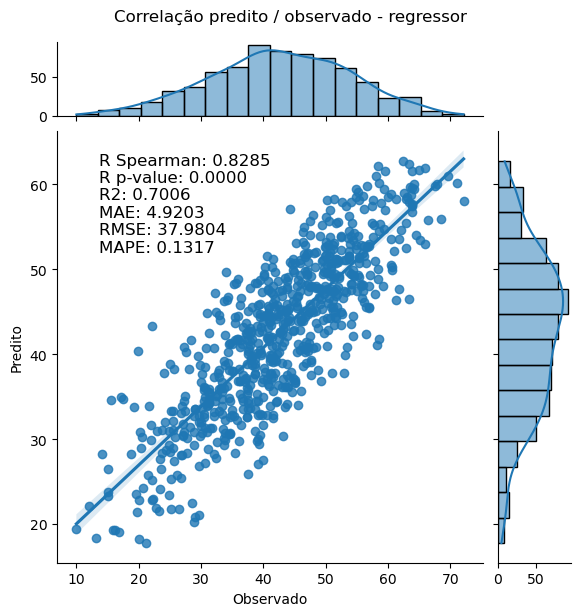

In [10]:
regressor = Regression(df=df_train)

metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 10
svm__epsilon -> 0.2
svm__kernel -> linear
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundidade_lei

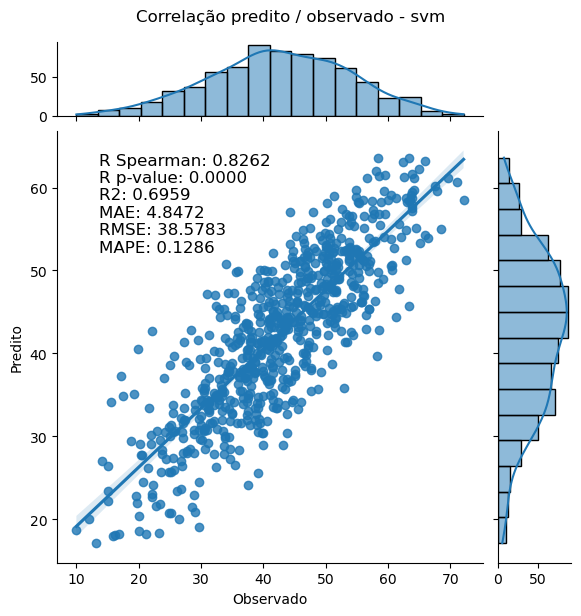

In [11]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__n_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundid

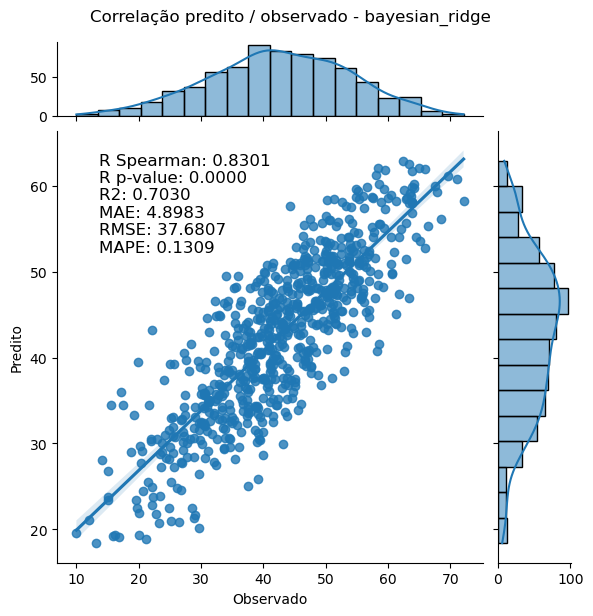

In [12]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.0001
nn__optimizer -> SGD
nn__epochs -> 100
nn__batch_size -> 16
nn__activation2 -> sigmoid
nn__activation1 -> softmax
feature_selection__k -> all
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_

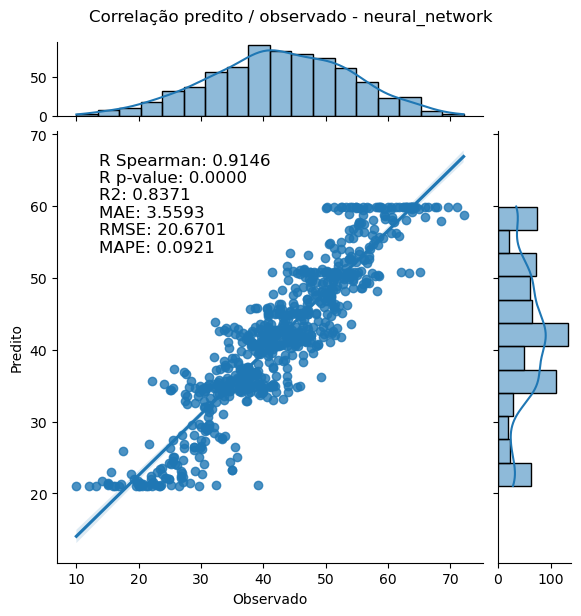

In [13]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [15]:
df_metricas_train = organizar_metricas(
    {
        "regressor": metricas_regr,
        "svm": metricas_svm,
        "bayesian_ridge": metricas_nb,
        "neural_network": metricas_nn,
    }
)
df_metricas_train

,metricas,valores,modelo
0,R Spearman,0.8285,Regressão Linear Múltipla
1,R p-value,0.0000,Regressão Linear Múltipla
2,R2,0.7006,Regressão Linear Múltipla
3,MAE,4.9203,Regressão Linear Múltipla
4,RMSE,37.9804,Regressão Linear Múltipla
5,MAPE,0.1317,Regressão Linear Múltipla
6,R Spearman,0.8262,SVR
7,R p-value,0.0000,SVR
8,R2,0.6959,SVR
9,MAE,4.8472,SVR


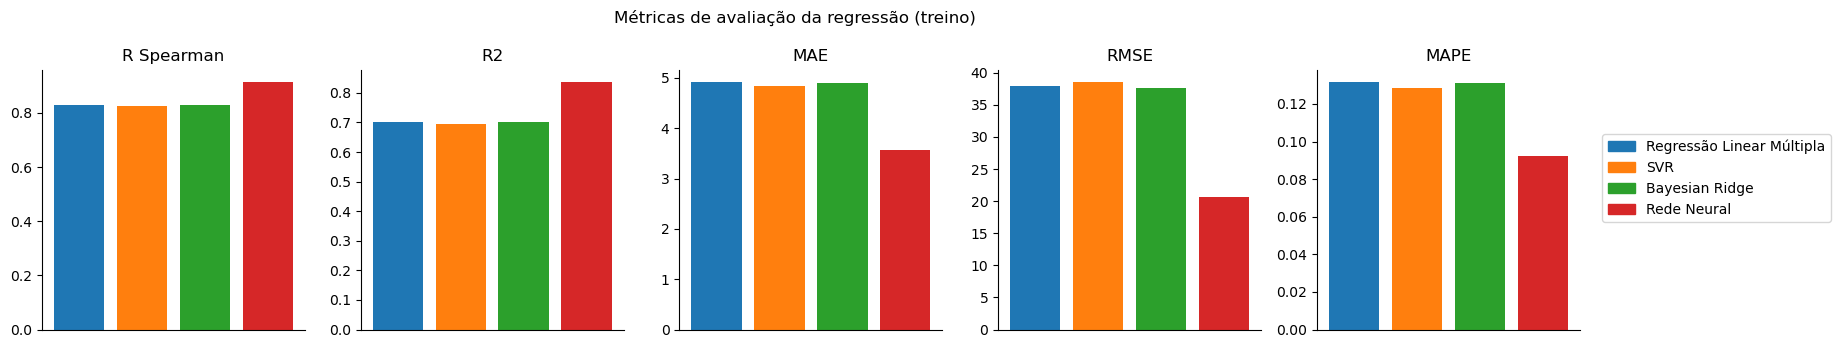

In [16]:
plotar_metricas(df_metricas_train, "Métricas de avaliação da regressão (treino)")

In [17]:
df_train[ALGORITMOS["regressor"]] = np.ravel(pred_regr)
df_train[ALGORITMOS["svm"]] = np.ravel(pred_svm)
df_train[ALGORITMOS["bayesian_ridge"]] = np.ravel(pred_nb)
df_train[ALGORITMOS["neural_network"]] = np.ravel(pred_nn)

df_train.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,gnomad_af_log,idade_inicio_sintomas,Regressão Linear Múltipla,SVR,Bayesian Ridge,Rede Neural
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.301653,-0.946900,1,1.0,0.346886,17.4,34.687721,34.913516,34.475803,25.853628
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.450245,-0.778728,0,1.0,0.553847,36.0,41.812608,41.215634,42.075194,35.961887
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.007599,-0.812363,0,0.0,-0.275561,42.0,44.192978,44.651824,44.984941,45.035622
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.413957,0.627190,1,1.0,-1.428356,24.8,30.898665,31.094390,31.584921,24.284252
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-1.947282,-0.220397,0,0.0,1.685460,44.2,57.146496,57.021185,57.666860,53.407337


# Validação

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundid

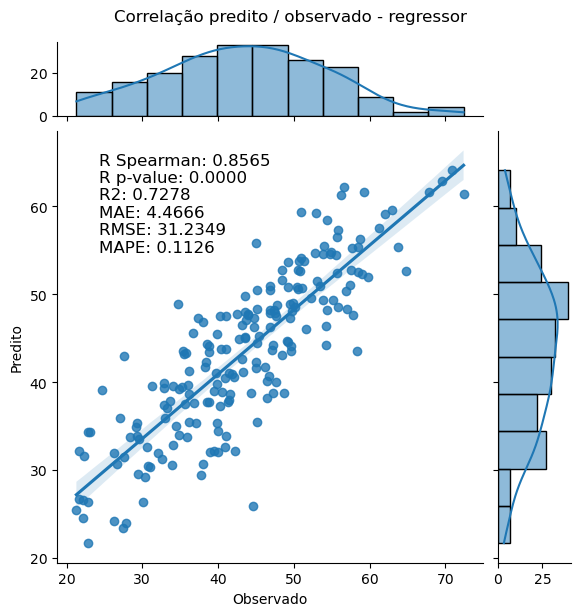

In [18]:
regressor = Regression(df=df_valid)

metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 10
svm__epsilon -> 0.2
svm__kernel -> linear
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundidade_lei

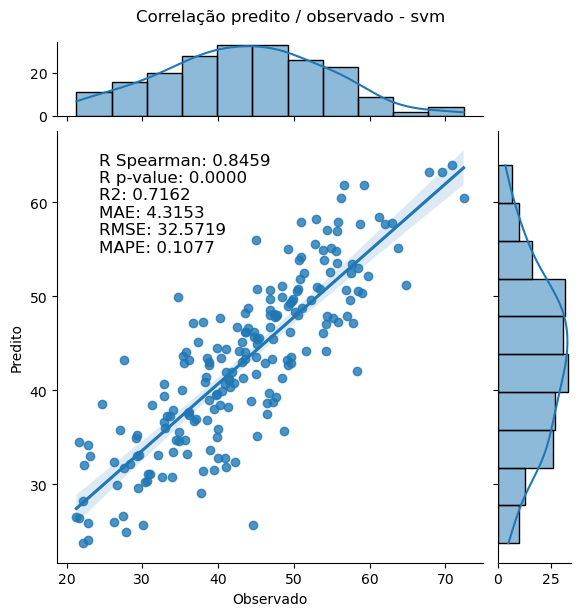

In [19]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__n_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundid

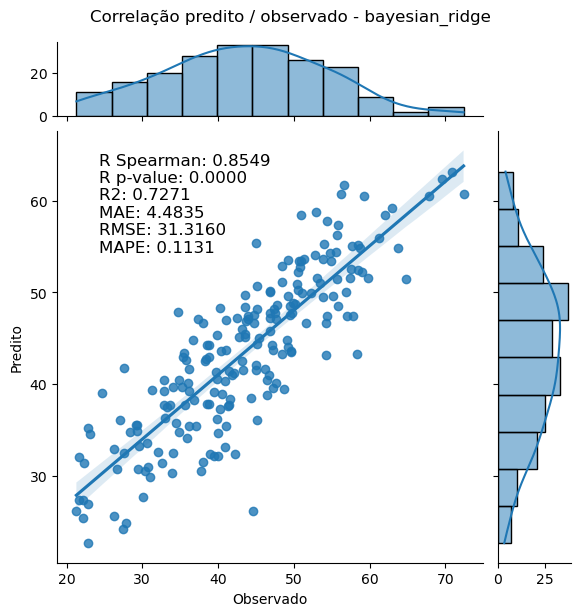

In [20]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.05
nn__optimizer -> SGD
nn__epochs -> 100
nn__batch_size -> 32
nn__activation2 -> tanh
nn__activation1 -> softmax
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__cadd_phred

--- Status de Cada Atributo no Pipeline ---
               Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
        num__tipo_variante_frameshift              True              False
          num__tipo_variante_missense              True              False
          num__tipo_variante_nonsense              True              False
              num__ancestralidade_AFR              True              False
              num__ancestralidade_AMR     

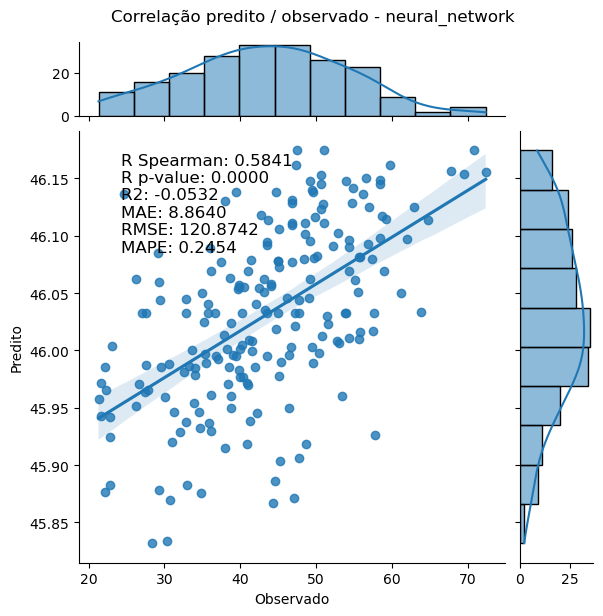

In [21]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [23]:
df_metricas_valid = organizar_metricas(
    {
        "regressor": metricas_regr,
        "svm": metricas_svm,
        "bayesian_ridge": metricas_nb,
        "neural_network": metricas_nn,
    }
)
df_metricas_valid

,metricas,valores,modelo
0,R Spearman,0.8565,Regressão Linear Múltipla
1,R p-value,0.0000,Regressão Linear Múltipla
2,R2,0.7278,Regressão Linear Múltipla
3,MAE,4.4666,Regressão Linear Múltipla
4,RMSE,31.2349,Regressão Linear Múltipla
5,MAPE,0.1126,Regressão Linear Múltipla
6,R Spearman,0.8459,SVR
7,R p-value,0.0000,SVR
8,R2,0.7162,SVR
9,MAE,4.3153,SVR


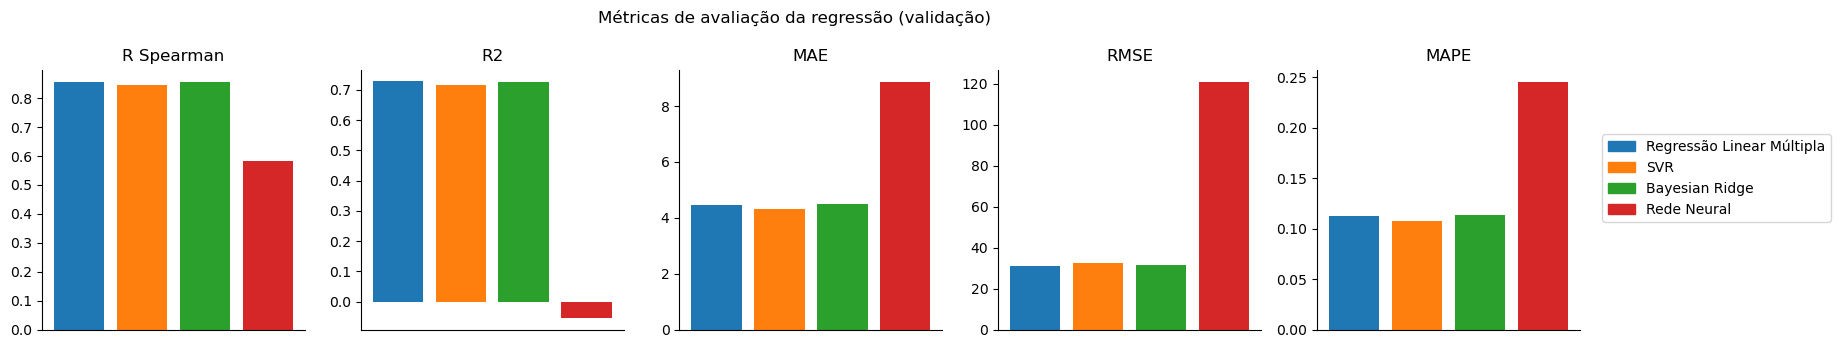

In [24]:
plotar_metricas(df_metricas_valid, "Métricas de avaliação da regressão (validação)")

In [25]:
df_valid[ALGORITMOS["regressor"]] = np.ravel(pred_regr)
df_valid[ALGORITMOS["svm"]] = np.ravel(pred_svm)
df_valid[ALGORITMOS["bayesian_ridge"]] = np.ravel(pred_nb)
df_valid[ALGORITMOS["neural_network"]] = np.ravel(pred_nn)

df_valid.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,gnomad_af_log,idade_inicio_sintomas,Regressão Linear Múltipla,SVR,Bayesian Ridge,Rede Neural
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.585023,0.156308,1,0.0,-1.428356,61.2,57.485734,58.440806,55.934810,46.050014
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,-1.321527,0.647371,0,0.0,1.635265,45.1,48.340654,45.453496,48.149354,46.105709
2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,-0.545302,0.183216,0,0.0,1.174626,69.5,62.873373,63.193834,62.323282,46.153576
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-1.084560,1.205702,0,1.0,1.555511,34.9,39.150660,35.617052,40.412457,46.050064
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.413379,0.210123,0,1.0,0.043893,56.9,50.333706,50.678948,50.016952,46.092709


# Teste

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundid

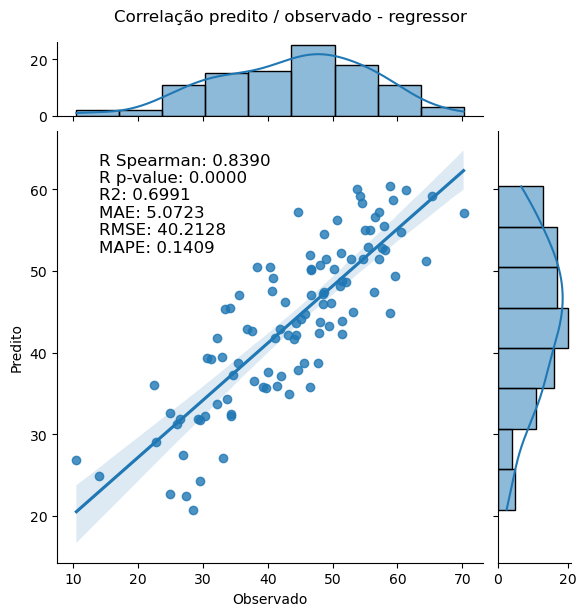

In [26]:
regressor = Regression(df=df_test)

metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 1
svm__epsilon -> 0.2
svm__kernel -> linear
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundidade_leit

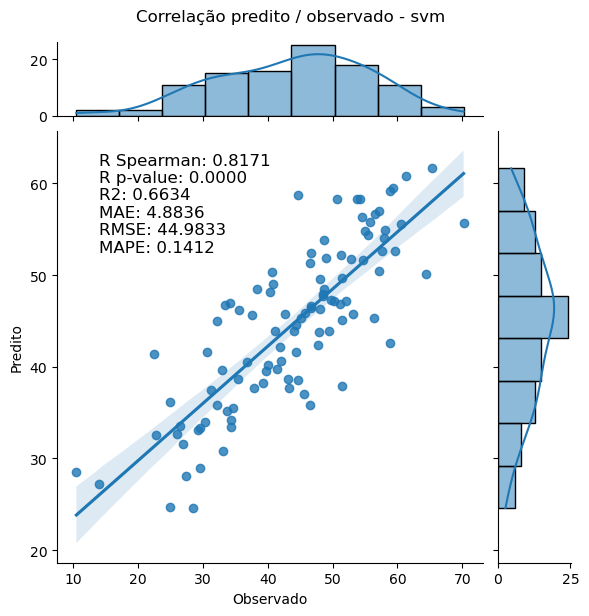

In [27]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__n_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    22

--- Lista das Variáveis Selecionadas ---
1. num__tipo_variante_frameshift
2. num__tipo_variante_missense
3. num__tipo_variante_nonsense
4. num__ancestralidade_AFR
5. num__ancestralidade_AMR
6. num__ancestralidade_Desconhecido
7. num__ancestralidade_EAS
8. num__ancestralidade_EUR
9. num__ancestralidade_SAS
10. num__gene_HTT
11. num__gene_LRRK2
12. num__gene_PSEN1
13. num__gene_SOD1
14. num__classificacao_clinica_Benigna
15. num__classificacao_clinica_Patogenica
16. num__classificacao_clinica_VUS
17. num__cadd_phred
18. num__conservacao_phylop
19. num__profundid

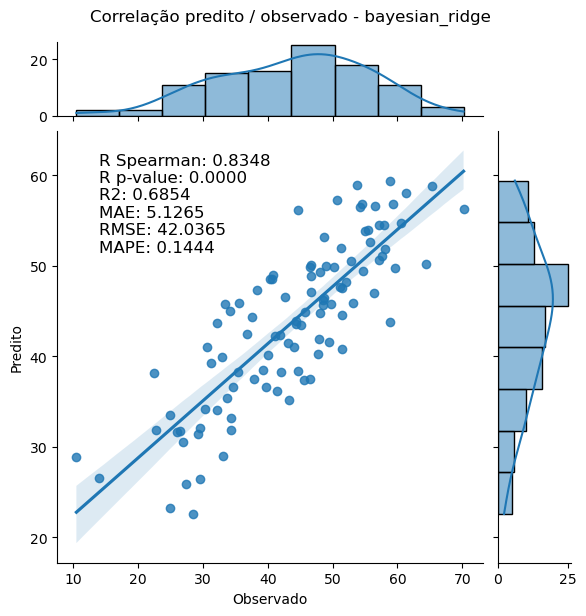

In [28]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 100
nn__batch_size -> 16
nn__activation2 -> softmax
nn__activation1 -> sigmoid
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 22
Total de variáveis após VarianceThreshold:    22
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__gene_HTT

--- Status de Cada Atributo no Pipeline ---
               Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
        num__tipo_variante_frameshift              True              False
          num__tipo_variante_missense              True              False
          num__tipo_variante_nonsense              True              False
              num__ancestralidade_AFR              True              False
              num__ancestralidade_AMR    

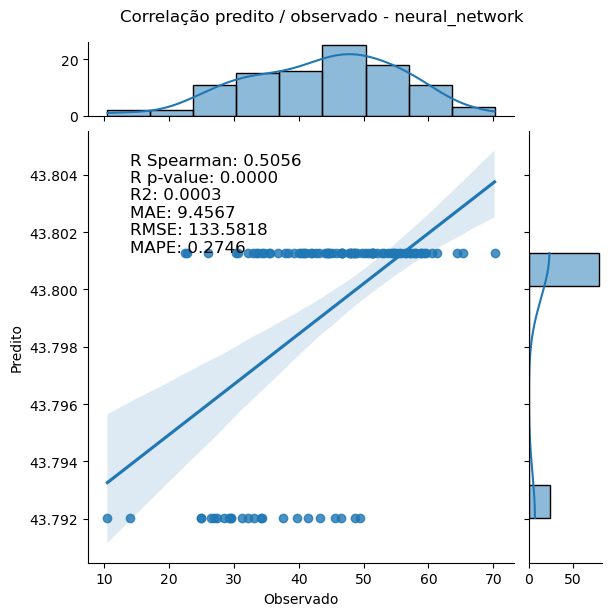

In [29]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=5)

In [31]:
df_metricas_test = organizar_metricas(
    {
        "regressor": metricas_regr,
        "svm": metricas_svm,
        "bayesian_ridge": metricas_nb,
        "neural_network": metricas_nn,
    }
)
df_metricas_test

,metricas,valores,modelo
0,R Spearman,0.8390,Regressão Linear Múltipla
1,R p-value,0.0000,Regressão Linear Múltipla
2,R2,0.6991,Regressão Linear Múltipla
3,MAE,5.0723,Regressão Linear Múltipla
4,RMSE,40.2128,Regressão Linear Múltipla
5,MAPE,0.1409,Regressão Linear Múltipla
6,R Spearman,0.8171,SVR
7,R p-value,0.0000,SVR
8,R2,0.6634,SVR
9,MAE,4.8836,SVR


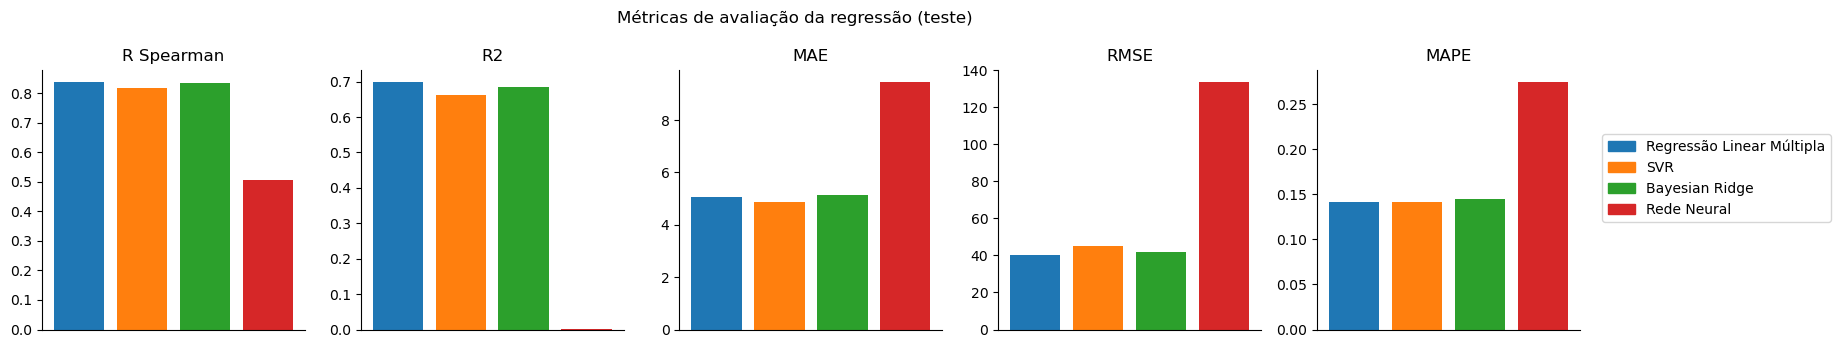

In [32]:
plotar_metricas(df_metricas_test, "Métricas de avaliação da regressão (teste)")

In [33]:
df_test[ALGORITMOS["regressor"]] = np.ravel(pred_regr)
df_test[ALGORITMOS["svm"]] = np.ravel(pred_svm)
df_test[ALGORITMOS["bayesian_ridge"]] = np.ravel(pred_nb)
df_test[ALGORITMOS["neural_network"]] = np.ravel(pred_nn)

df_test.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,gnomad_af_log,idade_inicio_sintomas,Regressão Linear Múltipla,SVR,Bayesian Ridge,Rede Neural
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.011977,1.817848,1,1.0,0.344445,37.9,36.485482,37.700060,37.503532,43.801262
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-1.275575,0.929900,0,0.0,0.609509,34.2,45.454381,46.986010,44.993982,43.792038
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-1.651299,1.494958,1,0.0,0.418307,59.3,58.723944,59.500284,56.896876,43.801262
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.208526,1.838029,0,0.0,0.979071,50.2,50.228471,47.134817,49.850794,43.801262
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.867993,-0.523107,0,0.0,0.688628,46.7,50.145517,52.392312,50.119105,43.801262


# Avalia Modelos

In [34]:
# Salva os resultados (joblib)
dump(df_train, f"{DIR_DADOS}/df_train_resultados_regression")
dump(df_valid, f"{DIR_DADOS}/df_valid_resultados_regression")
dump(df_test, f"{DIR_DADOS}/df_test_resultados_regression")

['./results/split_dataset/df_test_resultados_regression']

In [35]:
def testar_hipotese(y_pred_treino: pd.Series, y_pred_teste: pd.Series) -> None:
    """
    Compara a distribuição das previsões do treino com a do teste usando
    Kolmogorov-Smirnov (distribuição), Teste T de Welch (médias),
    Mann-Whitney (posição/medianas) e Levene (variâncias).

    Parâmetros:
        y_pred_treino : pd.Series
            Previsões do conjunto de treino.
        y_pred_teste : pd.Series
            Previsões do conjunto de teste.
    Retorna:
        None
    """
    ks_stat, p_v_ks = ks_2samp(y_pred_treino, y_pred_teste)
    t_stat, p_val_t = ttest_ind(y_pred_treino, y_pred_teste, equal_var=False)
    u_stat, p_val_u = mannwhitneyu(y_pred_treino, y_pred_teste, alternative="two-sided")
    w_stat, p_val_levene = levene(y_pred_treino, y_pred_teste)

    def interpretar(nome_teste, p_valor, stat, alfa=0.05):
        resultado = (
            "DIFERENTES (Rejeita H0)"
            if p_valor < alfa
            else "IGUAIS (Falha ao rejeitar H0)"
        )
        print(
            f"{nome_teste:<25} | estatística: {stat:.4f} | p-valor: {p_valor:.4f} | Conclusão: {resultado}"
        )

    print("=== Resultados dos Testes Estatísticos ===\n")
    interpretar("Teste Kolmogorov-Smirnov", p_v_ks, ks_stat)
    interpretar("Teste T (Médias)", p_val_t, t_stat)
    interpretar("Mann-Whitney (Medianas)", p_val_u, u_stat)
    interpretar("Levene (Variâncias)", p_val_levene, w_stat)

In [36]:
for nome in ALGORITMOS.values():
    print(f"\n\nTestando a hipótese para o modelo: {nome}")
    testar_hipotese(
        y_pred_treino=df_train[nome],
        y_pred_teste=df_test[nome],
    )



Testando a hipótese para o modelo: Regressão Linear Múltipla
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.1008 | p-valor: 0.2970 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Teste T (Médias)          | estatística: -1.2492 | p-valor: 0.2138 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 33769.0000 | p-valor: 0.1733 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 0.2664 | p-valor: 0.6059 | Conclusão: IGUAIS (Falha ao rejeitar H0)


Testando a hipótese para o modelo: SVR
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.1241 | p-valor: 0.1137 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Teste T (Médias)          | estatística: -2.4156 | p-valor: 0.0170 | Conclusão: DIFERENTES (Rejeita H0)
Mann-Whitney (Medianas)   | estatística: 31985.0000 | p-valor: 0.0310 | Conclusão: DIFERENTES (Rejeita H0)
Levene (Variâncias)       | estatística: 1.2212